<a href="https://colab.research.google.com/github/benameur21/Visual-Embeddings/blob/main/TP4_Embeddings_Visuels.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!git clone https://github.com/benameur21/Visual-Embeddings.git

Cloning into 'Visual-Embeddings'...
remote: Enumerating objects: 6, done.
remote: Counting objects: 100% (6/6), done.
remote: Compressing objects: 100% (4/4), done.
remote: Total 6 (delta 0), reused 3 (delta 0), pack-reused 0 (from 0)
Receiving objects: 100% (6/6), done.


In [2]:
%cd Visual-Embeddings


/content/Visual-Embeddings


In [3]:
!git status

On branch main
Your branch is up to date with 'origin/main'.

nothing to commit, working tree clean


In [4]:
!pip install -q tensorflow-datasets importlib_resources


**Importations**

In [5]:
# Gestion du hasard
import random
# Manipulation numérique
import numpy as np
# Affichage
import matplotlib.pyplot as plt
# Deep Learning
import tensorflow as tf
# Datasets TensorFlow
import tensorflow_datasets as tfds

In [6]:
# Choisir une graine personnelle
SEED = int(
 input("Entrez une SEED personnelle entre 1000 et 999999 : ")
)
# Générateurs utilisés dans les différentes parties
rng1 = random.Random(SEED + 1)
rng2 = random.Random(SEED + 2)
rng3 = random.Random(SEED + 3)
print("SEED utilisée :", SEED)

Entrez une SEED personnelle entre 1000 et 999999 : 202610
SEED utilisée : 202610


Partie 0 — Découvrir Oxford-IIIT Pet
**bold text**

Charger le dataset


In [7]:
# Charger le jeu d'entraînement
dataset, info = tfds.load(
 "oxford_iiit_pet",
 split="train",
 as_supervised=True, # Retourne (image, label)
 with_info=True # Informations sur le dataset
)
# Noms des races
class_names = info.features["label"].names
print("Nombre de classes :", len(class_names))
print(class_names)


Dl Completed...: 0 url [00:00, ? url/s]

Dl Size...: 0 MiB [00:00, ? MiB/s]

Extraction completed...: 0 file [00:00, ? file/s]

Generating splits...:   0%|          | 0/2 [00:00<?, ? splits/s]

Generating train examples...: 0 examples [00:00, ? examples/s]

Shuffling /root/tensorflow_datasets/oxford_iiit_pet/incomplete.IW040D_4.0.0/oxford_iiit_pet-train.tfrecord-[0-…

Generating test examples...: 0 examples [00:00, ? examples/s]

Shuffling /root/tensorflow_datasets/oxford_iiit_pet/incomplete.IW040D_4.0.0/oxford_iiit_pet-test.tfrecord-[0-9…

Dataset oxford_iiit_pet downloaded and prepared to /root/tensorflow_datasets/oxford_iiit_pet/4.0.0. Subsequent calls will reuse this data.
Nombre de classes : 37
['Abyssinian', 'american_bulldog', 'american_pit_bull_terrier', 'basset_hound', 'beagle', 'Bengal', 'Birman', 'Bombay', 'boxer', 'British_Shorthair', 'chihuahua', 'Egyptian_Mau', 'english_cocker_spaniel', 'english_setter', 'german_shorthaired', 'great_pyrenees', 'havanese', 'japanese_chin', 'keeshond', 'leonberger', 'Maine_Coon', 'miniature_pinscher', 'newfoundland', 'Persian', 'pomeranian', 'pug', 'Ragdoll', 'Russian_Blue', 'saint_bernard', 'samoyed', 'scottish_terrier', 'shiba_inu', 'Siamese', 'Sphynx', 'staffordshire_bull_terrier', 'wheaten_terrier', 'yorkshire_terrier']


Afficher quelques images


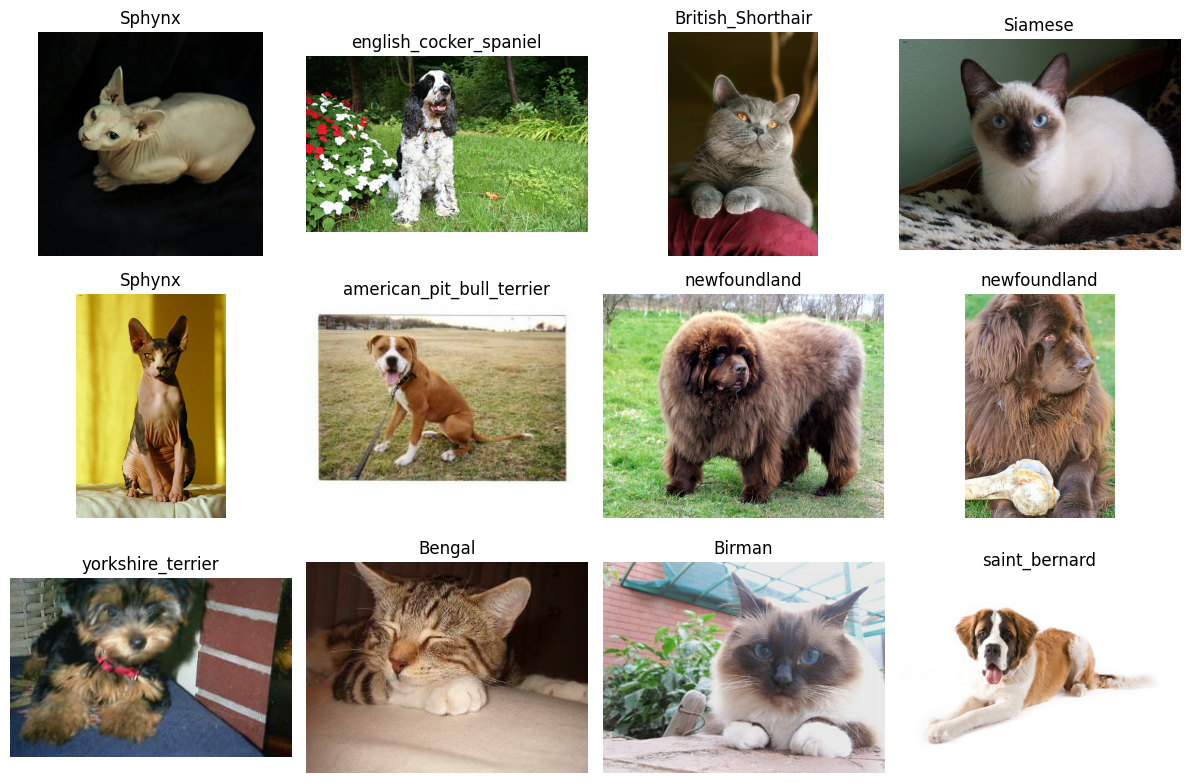

In [8]:
plt.figure(figsize=(12, 8))
# Afficher 12 images
for i, (image, label) in enumerate(dataset.take(12)):
 ax = plt.subplot(3, 4, i + 1)
 # Afficher l'image
 ax.imshow(image.numpy())
 # Afficher la race
 ax.set_title(
 class_names[int(label)]
 )
 ax.axis("off")
plt.tight_layout()
plt.show()